In [2]:
!pip install tensorflow==2.15

In [3]:
import tensorflow as tf

In [4]:
!mkdir -p ~/.kaggle
!cp "/content/kaggle.json" ~/.kaggle/kaggle.json

In [5]:
!kaggle datasets download -d mohammadelsayedfahmy/historicaluberdata

Dataset URL: https://www.kaggle.com/datasets/mohammadelsayedfahmy/historicaluberdata
License(s): unknown
historicaluberdata.zip: Skipping, found more recently modified local copy (use --force to force download)


In [6]:
!unzip /content/historicaluberdata.zip

Archive:  /content/historicaluberdata.zip
replace UberDataSet.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: UberDataSet.csv         


In [7]:
import pandas as pd
import numpy as np

In [8]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import plotly.express as px
from sklearn import ensemble
from sklearn import metrics
import warnings
warnings.filterwarnings("ignore")

In [9]:
uber=pd.read_csv('/content/UberDataSet.csv')

In [10]:
uber

,Unnamed: 0,id,timestamp,hour,day,month,datetime,timezone,source,destination,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,12,009e9c53-074d-43cf-aef2-0fbc7a47ed3d,1.543616e+09,22,30,11,2018-11-30 22:13:01,America/New_York,North End,West End,...,0.0003,1543593600,28.79,1543579200,42.52,1543600800,26.41,1543575600,40.53,1543611600
1,13,23f145da-f0c1-4d1f-a184-496bc003a7db,1.544698e+09,10,13,12,2018-12-13 10:50:11,America/New_York,North End,West End,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800
2,14,357559cb-8c58-4278-a41a-e33b2e0997a3,1.544729e+09,19,13,12,2018-12-13 19:15:03,America/New_York,North End,West End,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800
3,15,50ef1165-9d23-416c-a65c-18906207b295,1.545005e+09,23,16,12,2018-12-16 23:55:11,America/New_York,North End,West End,...,0.1252,1544979600,39.22,1544954400,43.83,1544990400,33.98,1545019200,38.38,1544986800
4,16,91c4861c-1780-42b0-bca1-bbd64a422cc3,1.544748e+09,0,14,12,2018-12-14 00:40:07,America/New_York,North End,West End,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385658,693066,616d3611-1820-450a-9845-a9ff304a4842,1.543708e+09,23,1,12,2018-12-01 23:53:05,America/New_York,West End,North End,...,0.0000,1543683600,31.42,1543658400,44.76,1543690800,27.77,1543658400,44.09,1543690800
385659,693067,633a3fc3-1f86-4b9e-9d48-2b7132112341,1.543708e+09,23,1,12,2018-12-01 23:53:05,America/New_York,West End,North End,...,0.0000,1543683600,31.42,1543658400,44.76,1543690800,27.77,1543658400,44.09,1543690800
385660,693068,64d451d0-639f-47a4-9b7c-6fd92fbd264f,1.543708e+09,23,1,12,2018-12-01 23:53:05,America/New_York,West End,North End,...,0.0000,1543683600,31.42,1543658400,44.76,1543690800,27.77,1543658400,44.09,1543690800
385661,693069,727e5f07-a96b-4ad1-a2c7-9abc3ad55b4e,1.543708e+09,23,1,12,2018-12-01 23:53:05,America/New_York,West End,North End,...,0.0000,1543683600,31.42,1543658400,44.76,1543690800,27.77,1543658400,44.09,1543690800


In [11]:
uber.head()

,Unnamed: 0,id,timestamp,hour,day,month,datetime,timezone,source,destination,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,12,009e9c53-074d-43cf-aef2-0fbc7a47ed3d,1.543616e+09,22,30,11,2018-11-30 22:13:01,America/New_York,North End,West End,...,0.0003,1543593600,28.79,1543579200,42.52,1543600800,26.41,1543575600,40.53,1543611600
1,13,23f145da-f0c1-4d1f-a184-496bc003a7db,1.544698e+09,10,13,12,2018-12-13 10:50:11,America/New_York,North End,West End,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800
2,14,357559cb-8c58-4278-a41a-e33b2e0997a3,1.544729e+09,19,13,12,2018-12-13 19:15:03,America/New_York,North End,West End,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800
3,15,50ef1165-9d23-416c-a65c-18906207b295,1.545005e+09,23,16,12,2018-12-16 23:55:11,America/New_York,North End,West End,...,0.1252,1544979600,39.22,1544954400,43.83,1544990400,33.98,1545019200,38.38,1544986800
4,16,91c4861c-1780-42b0-bca1-bbd64a422cc3,1.544748e+09,0,14,12,2018-12-14 00:40:07,America/New_York,North End,West End,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800


In [12]:
print(uber.info())
print(uber.describe())
print(uber.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 385663 entries, 0 to 385662
Data columns (total 58 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   385663 non-null  int64  
 1   id                           385663 non-null  object 
 2   timestamp                    385663 non-null  float64
 3   hour                         385663 non-null  int64  
 4   day                          385663 non-null  int64  
 5   month                        385663 non-null  int64  
 6   datetime                     385663 non-null  object 
 7   timezone                     385663 non-null  object 
 8   source                       385663 non-null  object 
 9   destination                  385663 non-null  object 
 10  cab_type                     385663 non-null  object 
 11  product_id                   385663 non-null  object 
 12  name                         385663 non-null  object 
 13 

In [13]:
print(uber.isnull().sum())

Unnamed: 0                         0
id                                 0
timestamp                          0
hour                               0
day                                0
month                              0
datetime                           0
timezone                           0
source                             0
destination                        0
cab_type                           0
product_id                         0
name                               0
price                          55095
distance                           0
surge_multiplier                   0
latitude                           0
longitude                          0
temperature                        0
apparentTemperature                0
short_summary                      0
long_summary                       0
precipIntensity                    0
precipProbability                  0
humidity                           0
windSpeed                          0
windGust                           0
w

In [14]:
uber.columns

Index(['Unnamed: 0', 'id', 'timestamp', 'hour', 'day', 'month', 'datetime',
       'timezone', 'source', 'destination', 'cab_type', 'product_id', 'name',
       'price', 'distance', 'surge_multiplier', 'latitude', 'longitude',
       'temperature', 'apparentTemperature', 'short_summary', 'long_summary',
       'precipIntensity', 'precipProbability', 'humidity', 'windSpeed',
       'windGust', 'windGustTime', 'visibility', 'temperatureHigh',
       'temperatureHighTime', 'temperatureLow', 'temperatureLowTime',
       'apparentTemperatureHigh', 'apparentTemperatureHighTime',
       'apparentTemperatureLow', 'apparentTemperatureLowTime', 'icon',
       'dewPoint', 'pressure', 'windBearing', 'cloudCover', 'uvIndex',
       'visibility.1', 'ozone', 'sunriseTime', 'sunsetTime', 'moonPhase',
       'precipIntensityMax', 'uvIndexTime', 'temperatureMin',
       'temperatureMinTime', 'temperatureMax', 'temperatureMaxTime',
       'apparentTemperatureMin', 'apparentTemperatureMinTime',
       'ap

In [15]:
uber['cab_type'].value_counts()

,count
cab_type,
Uber,385663


In [16]:
uber.product_id.value_counts()

,count
product_id,
6f72dfc5-27f1-42e8-84db-ccc7a75f6969,55096
9a0e7b09-b92b-4c41-9779-2ad22b4d779d,55096
6d318bcc-22a3-4af6-bddd-b409bfce1546,55096
6c84fd89-3f11-4782-9b50-97c468b19529,55095
8cf7e821-f0d3-49c6-8eba-e679c0ebcf6a,55095
55c66225-fbe7-4fd5-9072-eab1ece5e23e,55094
997acbb5-e102-41e1-b155-9df7de0a73f2,55091


In [17]:
uber['name'].value_counts()

,count
name,
UberXL,55096
WAV,55096
Black SUV,55096
Black,55095
Taxi,55095
UberX,55094
UberPool,55091


In [18]:
uber.shape

(385663, 58)

In [19]:
# Step 5:  Duplicates
uber.duplicated().sum()

0

In [20]:
uber.dropna(inplace=True)

In [21]:
uber.timezone.value_counts()

,count
timezone,
America/New_York,330568


In [22]:
uber=uber.reset_index()
uber = uber.drop(['Unnamed: 0','product_id','long_summary','index',], axis=1 )
uber.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330568 entries, 0 to 330567
Data columns (total 55 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           330568 non-null  object 
 1   timestamp                    330568 non-null  float64
 2   hour                         330568 non-null  int64  
 3   day                          330568 non-null  int64  
 4   month                        330568 non-null  int64  
 5   datetime                     330568 non-null  object 
 6   timezone                     330568 non-null  object 
 7   source                       330568 non-null  object 
 8   destination                  330568 non-null  object 
 9   cab_type                     330568 non-null  object 
 10  name                         330568 non-null  object 
 11  price                        330568 non-null  float64
 12  distance                     330568 non-null  float64
 13 

In [23]:
uber.rename(columns={'name': 'service_type','icon':'weather_condition'}, inplace=True)
uber.head(2)

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,009e9c53-074d-43cf-aef2-0fbc7a47ed3d,1.543616e+09,22,30,11,2018-11-30 22:13:01,America/New_York,North End,West End,Uber,...,0.0003,1543593600,28.79,1543579200,42.52,1543600800,26.41,1543575600,40.53,1543611600
1,23f145da-f0c1-4d1f-a184-496bc003a7db,1.544698e+09,10,13,12,2018-12-13 10:50:11,America/New_York,North End,West End,Uber,...,0.0001,1544716800,18.29,1544688000,33.83,1544731200,13.79,1544688000,32.85,1544734800


In [24]:
uber.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330568 entries, 0 to 330567
Data columns (total 55 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           330568 non-null  object 
 1   timestamp                    330568 non-null  float64
 2   hour                         330568 non-null  int64  
 3   day                          330568 non-null  int64  
 4   month                        330568 non-null  int64  
 5   datetime                     330568 non-null  object 
 6   timezone                     330568 non-null  object 
 7   source                       330568 non-null  object 
 8   destination                  330568 non-null  object 
 9   cab_type                     330568 non-null  object 
 10  service_type                 330568 non-null  object 
 11  price                        330568 non-null  float64
 12  distance                     330568 non-null  float64
 13 

In [25]:
uber.to_csv(r'CleanData.csv')

In [26]:
uber.describe()

,timestamp,hour,day,month,price,distance,surge_multiplier,latitude,longitude,temperature,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
count,3.305680e+05,330568.000000,330568.000000,330568.000000,330568.000000,330568.000000,330568.0,330568.000000,330568.000000,330568.000000,...,330568.000000,3.305680e+05,330568.000000,3.305680e+05,330568.000000,3.305680e+05,330568.000000,3.305680e+05,330568.000000,3.305680e+05
mean,1.544046e+09,11.608864,17.820176,11.586028,15.795343,2.191386,1.0,42.337966,-71.066103,39.569407,...,0.037350,1.544044e+09,33.446267,1.544042e+09,45.241922,1.544048e+09,29.710821,1.544049e+09,41.970382,1.544048e+09
std,6.897122e+05,6.942370,9.973335,0.492544,8.560300,1.178973,0.0,0.048059,0.020325,6.720901,...,0.055203,6.917860e+05,6.470424,6.907706e+05,5.639561,6.907094e+05,7.117836,6.876799e+05,6.930120,6.916463e+05
min,1.543204e+09,0.000000,1.000000,11.000000,4.500000,0.020000,1.0,42.214800,-71.105400,18.910000,...,0.000000,1.543162e+09,15.630000,1.543122e+09,33.510000,1.543154e+09,11.810000,1.543136e+09,28.950000,1.543187e+09
25%,1.543444e+09,6.000000,13.000000,11.000000,9.000000,1.300000,1.0,42.350300,-71.081000,36.450000,...,0.000000,1.543421e+09,30.170000,1.543399e+09,42.570000,1.543439e+09,27.760000,1.543399e+09,36.570000,1.543439e+09
50%,1.543737e+09,12.000000,17.000000,12.000000,12.500000,2.170000,1.0,42.351900,-71.063100,40.490000,...,0.000400,1.543770e+09,34.240000,1.543727e+09,44.660000,1.543788e+09,30.130000,1.543745e+09,40.950000,1.543788e+09
75%,1.544828e+09,18.000000,28.000000,12.000000,21.500000,2.840000,1.0,42.364700,-71.054200,43.580000,...,0.091600,1.544807e+09,38.880000,1.544789e+09,46.910000,1.544814e+09,35.330000,1.544789e+09,44.090000,1.544818e+09
max,1.545161e+09,23.000000,30.000000,12.000000,89.500000,7.860000,1.0,42.366100,-71.033000,57.220000,...,0.145900,1.545152e+09,43.100000,1.545192e+09,57.870000,1.545109e+09,40.050000,1.545134e+09,57.200000,1.545109e+09


EDA

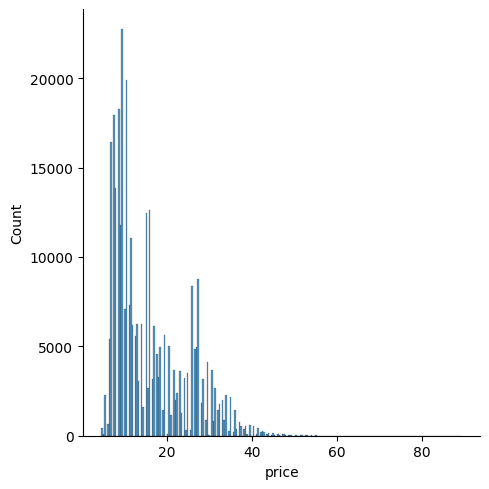

In [27]:
sns.displot(uber['price'])

<Axes: xlabel='service_type', ylabel='price'>

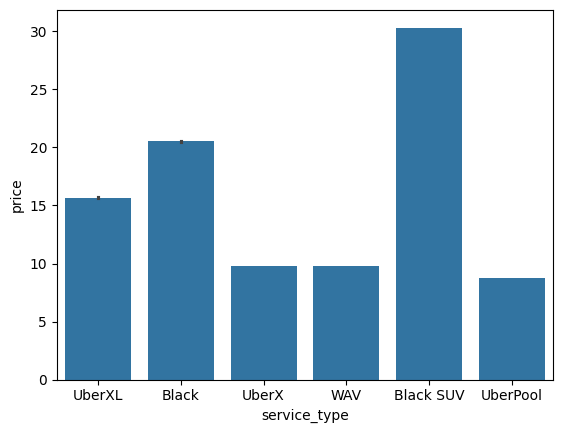

In [28]:
sns.barplot(x='service_type', y='price', data=uber)

<Axes: title={'center': 'Number of trips per Month '}, xlabel='month'>

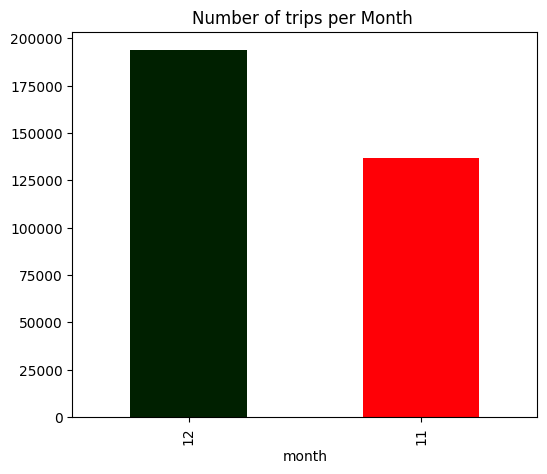

In [29]:
uber['month'].value_counts().plot(kind='bar', figsize=(6,5), color=['#002000','#ff0006'],title = "Number of trips per Month ")

In [30]:
pie = uber.weather_condition.value_counts().reset_index()
pie.columns = ['condition', 'count']
fig = px.pie(pie, values='count', names='condition', title='The proportion of number of trips in each weather condition', color_discrete_sequence=['#003f5c','#ffa600','#bc5090'], hole=0.2)
fig.show()

Feature engineering

In [31]:
uber.head(1)

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,009e9c53-074d-43cf-aef2-0fbc7a47ed3d,1.543616e+09,22,30,11,2018-11-30 22:13:01,America/New_York,North End,West End,Uber,...,0.0003,1543593600,28.79,1543579200,42.52,1543600800,26.41,1543575600,40.53,1543611600


In [32]:
uber.service_type.value_counts()

,count
service_type,
UberXL,55096
WAV,55096
Black SUV,55096
Black,55095
UberX,55094
UberPool,55091


In [33]:
uber.shape

(330568, 55)

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE

In [36]:
# Define Dependent Variable 'y'and independent variable 'X'
X = uber.drop('price', axis= 1)
y = uber['price']
print(X.shape)
print(y.shape)
R_sqaured = {}
Mean_SE = {}

(330568, 54)
(330568,)


In [37]:
#ٍSplitting data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 10)

def RFE_Function(i):
    reg = LinearRegression()
    rfe = RFE(reg , n_features_to_select = i)
    rfe = rfe.fit(X_train, y_train)
    selected_columns = X_train[X_train.columns[rfe.support_]]
    #Fitting training data
    reg = reg.fit(selected_columns, y_train)
    R_sqaured['Feature_'+str(i)]=reg.score(X_test[selected_columns.columns], y_test)
    y_pred = reg.predict(X_test[selected_columns.columns])
    Mean_SE['Feature_'+str(i)] = metrics.mean_squared_error(y_test,y_pred)
    return selected_columns

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from sklearn import metrics # Add this line to import the metrics module

In [39]:
# Define Dependent Variable 'y'and independent variable 'X'
X = uber.drop(['price', 'id'], axis= 1) # Assuming "id" is the problematic column
y = uber['price']
print(X.shape)
print(y.shape)
R_sqaured = {}
Mean_SE = {}

(330568, 53)
(330568,)


In [ ]:
X_55 = RFE_Function(55)
print("The R squared of 55 feature is ",R_sqaured['Feature_55'])
print("The MSE of 55 feature is ",Mean_SE['Feature_55'])
print(X_55.shape)